# Prior Biology in Gene Perturbation

> Research question: Does Prior Biology Help?

Test whether prior biology knowledge improves GEARS generalization to held-out combinatorial gene pairs by comparing three model variants:

- **Full GEARS** — both Gene Ontology (GO) functional prior *and* coexpression expression graph
- **Remove GO** — coexpression graph only (no functional prior)
- **Remove coexpression** — GO graph only (no expression graph)

In [ ]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import numpy as np


# import GEARS materials
_cwd = os.getcwd()
_path_candidates = [
    os.path.join(_cwd, "materials"),
    os.path.join(_cwd, "..", "materials")
]

for _c in _path_candidates:
    if _c not in sys.path and os.path.isdir(os.path.join(_c, "gears")):
        sys.path.insert(0, _c)
        break

from gears import PertData, GEARS
from gears.inference import evaluate, compute_metrics
from gears.utils import print_sys

In [15]:
ROOT = os.path.abspath(os.path.join('', os.pardir))
DATA_PATH = os.path.join(ROOT, 'data')
DATASET_NAME = 'norman'
DATASET_PATH = os.path.join(DATA_PATH, DATASET_NAME)

OUT_DIR = os.path.join(ROOT, 'PriorBiology')
MODEL_DIR = os.path.join(OUT_DIR, 'models')
RESULT_DIR = os.path.join(OUT_DIR, 'results')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

DEVICE = 'cpu'
EPOCHS = 1
LR = 1e-3
WEIGHT_DECAY = 5e-4
BATCH_SIZE = 8
TEST_BATCH_SIZE = 32 
SEED = 1
TRAIN_GENE_SET_SIZE = 0.75

print(f'Data path: {DATASET_PATH}')
print(f'Output dir: {OUT_DIR}')

Data path: /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/data/norman
Output dir: /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology


> #### Load perturbation data

In [16]:
pert_data = PertData(data_path=DATA_PATH, default_pert_graph=True)
pert_data.load(data_path=DATASET_PATH)
pert_data.prepare_split(split='simulation', seed=SEED, train_gene_set_size=TRAIN_GENE_SET_SIZE)
pert_data.get_dataloader(batch_size=BATCH_SIZE, test_batch_size=TEST_BATCH_SIZE)

Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['RHOXF2BB+ctrl' 'LYL1+IER5L' 'ctrl+IER5L' 'KIAA1804+ctrl' 'IER5L+ctrl'
 'RHOXF2BB+ZBTB25' 'RHOXF2BB+SET']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:9
combo_seen1:43
combo_seen2:19
unseen_single:36
Done!
Creating dataloaders....
Done!


here1


In [17]:
print('Loaded dataset:', pert_data.dataset_name)
print('Number of genes:', len(pert_data.gene_names))
print('Number of perturbations:', len(pert_data.pert_names))

print('Split:', pert_data.split)
print('Train gene set size:', pert_data.train_gene_set_size)
for k, v in pert_data.set2conditions.items():
    print(f'  {k}: {len(v)} conditions')

Loaded dataset: norman
Number of genes: 5045
Number of perturbations: 9853
Split: simulation
Train gene set size: 0.75
  test: 107 conditions
  train: 139 conditions
  val: 31 conditions


> #### Helper: train one GEARS variant
A variant is defined by how many GNN layers are applied to each graph:
- `num_go_gnn_layers=1` → GO functional prior enabled
- `num_go_gnn_layers=0` → GO prior removed
- `num_gene_gnn_layers=1` → coexpression graph enabled
- `num_gene_gnn_layers=0` → coexpression graph removed


In [18]:
def heldout_combo_mse(test_pert_res):
    """Mean MSE over held-out combinatorial pairs (combo perts, no ctrl)."""
    combo_perts = [p for p in test_pert_res if 'ctrl' not in p]
    if not combo_perts:
        return float('nan')
    return float(np.mean([test_pert_res[p]['mse'] for p in combo_perts]))


def train_variant(name, pert_data, num_go_gnn_layers, num_gene_gnn_layers):
    model = GEARS(pert_data, device=DEVICE, weight_bias_track=False)
    model.model_initialize(
        num_go_gnn_layers=num_go_gnn_layers,
        num_gene_gnn_layers=num_gene_gnn_layers,
    )
    model.train(epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)


    # Explicitly save the trained variant
    os.makedirs(MODEL_DIR, exist_ok=True)
    model.save_model(name)
    print(f'Saved {name} to {MODEL_DIR}')
    return model 

> #### Variant (a): Full GEARS — GO graph + coexpression graph

In [7]:
print_sys('Training variant: full GEARS (GO + coexpression)')
model_full = train_variant('full_gears', pert_data, num_go_gnn_layers=1, num_gene_gnn_layers=1)

Training variant: full GEARS (GO + coexpression)
Found local copy...
Start Training...
Epoch 1 Step 1 Train Loss: 0.5366
Epoch 1 Step 51 Train Loss: 0.5918
Epoch 1 Step 101 Train Loss: 0.4028
Epoch 1 Step 151 Train Loss: 0.3222
Epoch 1 Step 201 Train Loss: 0.4701
Epoch 1 Step 251 Train Loss: 0.4154
Epoch 1 Step 301 Train Loss: 0.3772
Epoch 1 Step 351 Train Loss: 0.5164
Epoch 1 Step 401 Train Loss: 0.4034
Epoch 1 Step 451 Train Loss: 0.3488
Epoch 1 Step 501 Train Loss: 0.3472
Epoch 1 Step 551 Train Loss: 0.4266
Epoch 1 Step 601 Train Loss: 0.4041
Epoch 1 Step 651 Train Loss: 0.3901
Epoch 1 Step 701 Train Loss: 0.4375
Epoch 1 Step 751 Train Loss: 0.3100
Epoch 1 Step 801 Train Loss: 0.3555
Epoch 1 Step 851 Train Loss: 0.4194
Epoch 1 Step 901 Train Loss: 0.5549
Epoch 1 Step 951 Train Loss: 0.4006
Epoch 1 Step 1001 Train Loss: 0.4846
Epoch 1 Step 1051 Train Loss: 0.5376
Epoch 1 Step 1101 Train Loss: 0.5346
Epoch 1 Step 1151 Train Loss: 0.6045
Epoch 1 Step 1201 Train Loss: 0.4151
Epoch 1 Ste

Saved full_gears to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology/models


In [8]:
"""
Training variant: full GEARS (GO + coexpression)
Found local copy...
Start Training...
Epoch 1 Step 1 Train Loss: 0.5366
Epoch 1 Step 51 Train Loss: 0.5918
Epoch 1 Step 101 Train Loss: 0.4028
Epoch 1 Step 151 Train Loss: 0.3222
Epoch 1 Step 201 Train Loss: 0.4701
Epoch 1 Step 251 Train Loss: 0.4154
Epoch 1 Step 301 Train Loss: 0.3772
Epoch 1 Step 351 Train Loss: 0.5164
Epoch 1 Step 401 Train Loss: 0.4034
Epoch 1 Step 451 Train Loss: 0.3488
Epoch 1 Step 501 Train Loss: 0.3472
Epoch 1 Step 551 Train Loss: 0.4266
Epoch 1 Step 601 Train Loss: 0.4041
Epoch 1 Step 651 Train Loss: 0.3901
Epoch 1 Step 701 Train Loss: 0.4375
Epoch 1 Step 751 Train Loss: 0.3100
Epoch 1 Step 801 Train Loss: 0.3555
Epoch 1 Step 851 Train Loss: 0.4194
Epoch 1 Step 901 Train Loss: 0.5549
Epoch 1 Step 951 Train Loss: 0.4006
Epoch 1 Step 1001 Train Loss: 0.4846
Epoch 1 Step 1051 Train Loss: 0.5376
Epoch 1 Step 1101 Train Loss: 0.5346
Epoch 1 Step 1151 Train Loss: 0.6045
Epoch 1 Step 1201 Train Loss: 0.4151
Epoch 1 Step 1251 Train Loss: 0.4860
Epoch 1 Step 1301 Train Loss: 0.4142
Epoch 1 Step 1351 Train Loss: 0.4296
Epoch 1 Step 1401 Train Loss: 0.5050
Epoch 1 Step 1451 Train Loss: 0.3767
Epoch 1 Step 1501 Train Loss: 0.4432
Epoch 1 Step 1551 Train Loss: 0.4110
Epoch 1 Step 1601 Train Loss: 0.4445
Epoch 1 Step 1651 Train Loss: 0.3839
Epoch 1 Step 1701 Train Loss: 0.3368
Epoch 1 Step 1751 Train Loss: 0.3576
Epoch 1 Step 1801 Train Loss: 0.4778
Epoch 1 Step 1851 Train Loss: 0.4724
Epoch 1 Step 1901 Train Loss: 0.4517
Epoch 1 Step 1951 Train Loss: 0.4522
Epoch 1 Step 2001 Train Loss: 0.4260
Epoch 1 Step 2051 Train Loss: 0.3931
Epoch 1 Step 2101 Train Loss: 0.4289
Epoch 1 Step 2151 Train Loss: 0.4464
Epoch 1 Step 2201 Train Loss: 0.3804
Epoch 1 Step 2251 Train Loss: 0.3340
Epoch 1 Step 2301 Train Loss: 0.4307
Epoch 1 Step 2351 Train Loss: 0.3786
Epoch 1 Step 2401 Train Loss: 0.4575
Epoch 1 Step 2451 Train Loss: 0.4861
Epoch 1 Step 2501 Train Loss: 0.6063
Epoch 1 Step 2551 Train Loss: 0.7159
Epoch 1 Step 2601 Train Loss: 0.4301
Epoch 1 Step 2651 Train Loss: 0.4131
Epoch 1 Step 2701 Train Loss: 0.5317
Epoch 1 Step 2751 Train Loss: 0.4130
Epoch 1 Step 2801 Train Loss: 0.3662
Epoch 1 Step 2851 Train Loss: 0.4489
Epoch 1 Step 2901 Train Loss: 0.3766
Epoch 1 Step 2951 Train Loss: 0.3379
Epoch 1 Step 3001 Train Loss: 0.4487
Epoch 1 Step 3051 Train Loss: 0.3702
Epoch 1 Step 3101 Train Loss: 0.4227
Epoch 1 Step 3151 Train Loss: 0.4147
Epoch 1 Step 3201 Train Loss: 0.3681
Epoch 1 Step 3251 Train Loss: 0.5006
Epoch 1 Step 3301 Train Loss: 0.4399
Epoch 1 Step 3351 Train Loss: 0.3791
Epoch 1 Step 3401 Train Loss: 0.4924
Epoch 1 Step 3451 Train Loss: 0.4533
Epoch 1 Step 3501 Train Loss: 0.4026
Epoch 1 Step 3551 Train Loss: 0.3776
Epoch 1 Step 3601 Train Loss: 0.3825
Epoch 1 Step 3651 Train Loss: 0.3701
Epoch 1 Step 3701 Train Loss: 0.3840
Epoch 1 Step 3751 Train Loss: 0.3947
Epoch 1 Step 3801 Train Loss: 0.6097
Epoch 1 Step 3851 Train Loss: 0.4953
Epoch 1 Step 3901 Train Loss: 0.3905
Epoch 1 Step 3951 Train Loss: 0.4202
Epoch 1 Step 4001 Train Loss: 0.4590
Epoch 1 Step 4051 Train Loss: 0.5261
Epoch 1 Step 4101 Train Loss: 0.3872
Epoch 1 Step 4151 Train Loss: 0.4714
Epoch 1 Step 4201 Train Loss: 0.4618
Epoch 1 Step 4251 Train Loss: 0.4729
Epoch 1 Step 4301 Train Loss: 0.5297
Epoch 1 Step 4351 Train Loss: 0.4095
Epoch 1 Step 4401 Train Loss: 0.4832
Epoch 1 Step 4451 Train Loss: 0.4954
Epoch 1 Step 4501 Train Loss: 0.4163
Epoch 1 Step 4551 Train Loss: 0.3929
Epoch 1 Step 4601 Train Loss: 0.4779
Epoch 1 Step 4651 Train Loss: 0.6494
Epoch 1 Step 4701 Train Loss: 0.3793
Epoch 1 Step 4751 Train Loss: 0.3588
Epoch 1 Step 4801 Train Loss: 0.3842
Epoch 1 Step 4851 Train Loss: 0.4362
Epoch 1 Step 4901 Train Loss: 0.5500
Epoch 1 Step 4951 Train Loss: 0.6939
Epoch 1 Step 5001 Train Loss: 0.5349
Epoch 1 Step 5051 Train Loss: 0.3076
Epoch 1 Step 5101 Train Loss: 0.4257
Epoch 1 Step 5151 Train Loss: 0.4523
Epoch 1 Step 5201 Train Loss: 0.4662
Epoch 1 Step 5251 Train Loss: 0.4850
Epoch 1 Step 5301 Train Loss: 0.5616
Epoch 1 Step 5351 Train Loss: 0.4177
Epoch 1 Step 5401 Train Loss: 0.3589
Epoch 1 Step 5451 Train Loss: 0.4184
Epoch 1 Step 5501 Train Loss: 0.3384
Epoch 1 Step 5551 Train Loss: 0.4894
Epoch 1 Step 5601 Train Loss: 0.4082
Epoch 1 Step 5651 Train Loss: 0.3907
Epoch 1 Step 5701 Train Loss: 0.4415
Epoch 1 Step 5751 Train Loss: 0.3525
Epoch 1 Step 5801 Train Loss: 0.3676
Epoch 1 Step 5851 Train Loss: 0.4524
Epoch 1 Step 5901 Train Loss: 0.3734
Epoch 1 Step 5951 Train Loss: 0.4456
Epoch 1 Step 6001 Train Loss: 0.5331
Epoch 1 Step 6051 Train Loss: 0.5746
Epoch 1 Step 6101 Train Loss: 0.4219
Epoch 1 Step 6151 Train Loss: 0.5462
Epoch 1 Step 6201 Train Loss: 0.4247
Epoch 1: Train Overall MSE: 0.0030 Validation Overall MSE: 0.0035. 
Train Top 20 DE MSE: 0.2085 Validation Top 20 DE MSE: 0.3300. 
Done!
Start Testing...
Best performing model: Test Top 20 DE MSE: 0.2872
Start doing subgroup analysis for simulation split...
test_combo_seen0_mse: 0.0054686659584856695
test_combo_seen0_pearson: 0.9832358
test_combo_seen0_mse_de: 0.23986074095591903
test_combo_seen0_pearson_de: 0.728924936718411
test_combo_seen1_mse: 0.006878113908812317
test_combo_seen1_pearson: 0.97995937
test_combo_seen1_mse_de: 0.29098743156984797
test_combo_seen1_pearson_de: 0.8420728528222372
test_combo_seen2_mse: 0.0048416564976306335
test_combo_seen2_pearson: 0.985363
test_combo_seen2_mse_de: 0.37653534192787974
test_combo_seen2_pearson_de: 0.8704037
test_unseen_single_mse: 0.0031958661735795126
test_unseen_single_pearson: 0.990185
test_unseen_single_mse_de: 0.24733641981341256
test_unseen_single_pearson_de: 0.8581525302595563
test_combo_seen0_pearson_delta: 0.5318009
test_combo_seen0_frac_opposite_direction_top20_non_dropout: 0.15555555555555556
test_combo_seen0_frac_sigma_below_1_non_dropout: 0.7833333333333333
test_combo_seen0_mse_top20_de_non_dropout: 0.3615969800286823
test_combo_seen1_pearson_delta: 0.48612496
test_combo_seen1_frac_opposite_direction_top20_non_dropout: 0.18255813953488373
test_combo_seen1_frac_sigma_below_1_non_dropout: 0.6686046511627908
test_combo_seen1_mse_top20_de_non_dropout: 0.3908899181284184
test_combo_seen2_pearson_delta: 0.47772017
test_combo_seen2_frac_opposite_direction_top20_non_dropout: 0.16578947368421051
test_combo_seen2_frac_sigma_below_1_non_dropout: 0.7105263157894737
test_combo_seen2_mse_top20_de_non_dropout: 0.40094220089285
test_unseen_single_pearson_delta: 0.28995982
test_unseen_single_frac_opposite_direction_top20_non_dropout: 0.2875
test_unseen_single_frac_sigma_below_1_non_dropout: 0.8402777777777778
test_unseen_single_mse_top20_de_non_dropout: 0.2745985650302221
Done!
Saved full_gears to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology/models
"""

'\nTraining variant: full GEARS (GO + coexpression)\nFound local copy...\nStart Training...\nEpoch 1 Step 1 Train Loss: 0.5366\nEpoch 1 Step 51 Train Loss: 0.5918\nEpoch 1 Step 101 Train Loss: 0.4028\nEpoch 1 Step 151 Train Loss: 0.3222\nEpoch 1 Step 201 Train Loss: 0.4701\nEpoch 1 Step 251 Train Loss: 0.4154\nEpoch 1 Step 301 Train Loss: 0.3772\nEpoch 1 Step 351 Train Loss: 0.5164\nEpoch 1 Step 401 Train Loss: 0.4034\nEpoch 1 Step 451 Train Loss: 0.3488\nEpoch 1 Step 501 Train Loss: 0.3472\nEpoch 1 Step 551 Train Loss: 0.4266\nEpoch 1 Step 601 Train Loss: 0.4041\nEpoch 1 Step 651 Train Loss: 0.3901\nEpoch 1 Step 701 Train Loss: 0.4375\nEpoch 1 Step 751 Train Loss: 0.3100\nEpoch 1 Step 801 Train Loss: 0.3555\nEpoch 1 Step 851 Train Loss: 0.4194\nEpoch 1 Step 901 Train Loss: 0.5549\nEpoch 1 Step 951 Train Loss: 0.4006\nEpoch 1 Step 1001 Train Loss: 0.4846\nEpoch 1 Step 1051 Train Loss: 0.5376\nEpoch 1 Step 1101 Train Loss: 0.5346\nEpoch 1 Step 1151 Train Loss: 0.6045\nEpoch 1 Step 1201 

> #### Variant (b): Remove GO — coexpression graph only

In [9]:
print_sys('Training variant: remove GO (coexpression only)')
model_remove_go = train_variant('remove_go', pert_data, num_go_gnn_layers=0, num_gene_gnn_layers=1)

Training variant: remove GO (coexpression only)
Found local copy...
Start Training...
Epoch 1 Step 1 Train Loss: 0.5398
Epoch 1 Step 51 Train Loss: 0.3328
Epoch 1 Step 101 Train Loss: 0.4645
Epoch 1 Step 151 Train Loss: 0.4709
Epoch 1 Step 201 Train Loss: 0.4749
Epoch 1 Step 251 Train Loss: 0.4516
Epoch 1 Step 301 Train Loss: 0.5983
Epoch 1 Step 351 Train Loss: 0.5404
Epoch 1 Step 401 Train Loss: 0.3965
Epoch 1 Step 451 Train Loss: 0.3764
Epoch 1 Step 501 Train Loss: 0.4266
Epoch 1 Step 551 Train Loss: 0.6202
Epoch 1 Step 601 Train Loss: 0.4517
Epoch 1 Step 651 Train Loss: 0.5029
Epoch 1 Step 701 Train Loss: 0.4761
Epoch 1 Step 751 Train Loss: 0.3982
Epoch 1 Step 801 Train Loss: 0.4948
Epoch 1 Step 851 Train Loss: 0.5114
Epoch 1 Step 901 Train Loss: 0.5462
Epoch 1 Step 951 Train Loss: 0.6511
Epoch 1 Step 1001 Train Loss: 0.4513
Epoch 1 Step 1051 Train Loss: 0.3773
Epoch 1 Step 1101 Train Loss: 0.3431
Epoch 1 Step 1151 Train Loss: 0.4370
Epoch 1 Step 1201 Train Loss: 0.3784
Epoch 1 Step

Saved remove_go to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology/models


In [ ]:
"""
Training variant: remove GO (coexpression only)
Found local copy...
Start Training...
Epoch 1 Step 1 Train Loss: 0.5398
Epoch 1 Step 51 Train Loss: 0.3328
Epoch 1 Step 101 Train Loss: 0.4645
Epoch 1 Step 151 Train Loss: 0.4709
Epoch 1 Step 201 Train Loss: 0.4749
Epoch 1 Step 251 Train Loss: 0.4516
Epoch 1 Step 301 Train Loss: 0.5983
Epoch 1 Step 351 Train Loss: 0.5404
Epoch 1 Step 401 Train Loss: 0.3965
Epoch 1 Step 451 Train Loss: 0.3764
Epoch 1 Step 501 Train Loss: 0.4266
Epoch 1 Step 551 Train Loss: 0.6202
Epoch 1 Step 601 Train Loss: 0.4517
Epoch 1 Step 651 Train Loss: 0.5029
Epoch 1 Step 701 Train Loss: 0.4761
Epoch 1 Step 751 Train Loss: 0.3982
Epoch 1 Step 801 Train Loss: 0.4948
Epoch 1 Step 851 Train Loss: 0.5114
Epoch 1 Step 901 Train Loss: 0.5462
Epoch 1 Step 951 Train Loss: 0.6511
Epoch 1 Step 1001 Train Loss: 0.4513
Epoch 1 Step 1051 Train Loss: 0.3773
Epoch 1 Step 1101 Train Loss: 0.3431
Epoch 1 Step 1151 Train Loss: 0.4370
Epoch 1 Step 1201 Train Loss: 0.3784
Epoch 1 Step 1251 Train Loss: 0.4426
Epoch 1 Step 1301 Train Loss: 0.4784
Epoch 1 Step 1351 Train Loss: 0.4118
Epoch 1 Step 1401 Train Loss: 0.6521
Epoch 1 Step 1451 Train Loss: 0.4006
Epoch 1 Step 1501 Train Loss: 0.3997
Epoch 1 Step 1551 Train Loss: 0.3801
Epoch 1 Step 1601 Train Loss: 0.3279
Epoch 1 Step 1651 Train Loss: 0.4261
Epoch 1 Step 1701 Train Loss: 0.4137
Epoch 1 Step 1751 Train Loss: 0.5572
Epoch 1 Step 1801 Train Loss: 0.4216
Epoch 1 Step 1851 Train Loss: 0.5157
Epoch 1 Step 1901 Train Loss: 0.5161
Epoch 1 Step 1951 Train Loss: 0.4289
Epoch 1 Step 2001 Train Loss: 0.6187
Epoch 1 Step 2051 Train Loss: 0.5077
Epoch 1 Step 2101 Train Loss: 0.5082
Epoch 1 Step 2151 Train Loss: 0.5123
Epoch 1 Step 2201 Train Loss: 0.4301
Epoch 1 Step 2251 Train Loss: 0.5373
Epoch 1 Step 2301 Train Loss: 0.3920
Epoch 1 Step 2351 Train Loss: 0.7666
Epoch 1 Step 2401 Train Loss: 0.3968
Epoch 1 Step 2451 Train Loss: 0.6451
Epoch 1 Step 2501 Train Loss: 0.5466
Epoch 1 Step 2551 Train Loss: 0.3544
Epoch 1 Step 2601 Train Loss: 0.3785
Epoch 1 Step 2651 Train Loss: 0.5855
Epoch 1 Step 2701 Train Loss: 0.3713
Epoch 1 Step 2751 Train Loss: 0.4438
Epoch 1 Step 2801 Train Loss: 0.4566
Epoch 1 Step 2851 Train Loss: 0.4156
Epoch 1 Step 2901 Train Loss: 0.3913
Epoch 1 Step 2951 Train Loss: 0.4398
Epoch 1 Step 3001 Train Loss: 0.4351
Epoch 1 Step 3051 Train Loss: 0.4452
Epoch 1 Step 3101 Train Loss: 0.5516
Epoch 1 Step 3151 Train Loss: 0.4822
Epoch 1 Step 3201 Train Loss: 0.4758
Epoch 1 Step 3251 Train Loss: 0.5643
Epoch 1 Step 3301 Train Loss: 0.5201
Epoch 1 Step 3351 Train Loss: 0.3301
Epoch 1 Step 3401 Train Loss: 0.3876
Epoch 1 Step 3451 Train Loss: 0.4993
Epoch 1 Step 3501 Train Loss: 0.6268
Epoch 1 Step 3551 Train Loss: 0.4358
Epoch 1 Step 3601 Train Loss: 0.3640
Epoch 1 Step 3651 Train Loss: 0.4589
Epoch 1 Step 3701 Train Loss: 0.8252
Epoch 1 Step 3751 Train Loss: 0.4024
Epoch 1 Step 3801 Train Loss: 0.6464
Epoch 1 Step 3851 Train Loss: 0.3464
Epoch 1 Step 3901 Train Loss: 0.5600
Epoch 1 Step 3951 Train Loss: 0.4384
Epoch 1 Step 4001 Train Loss: 0.4188
Epoch 1 Step 4051 Train Loss: 0.3636
Epoch 1 Step 4101 Train Loss: 0.4149
Epoch 1 Step 4151 Train Loss: 0.4925
Epoch 1 Step 4201 Train Loss: 0.5219
Epoch 1 Step 4251 Train Loss: 0.3748
Epoch 1 Step 4301 Train Loss: 0.5912
Epoch 1 Step 4351 Train Loss: 0.5785
Epoch 1 Step 4401 Train Loss: 0.5160
Epoch 1 Step 4451 Train Loss: 0.3690
Epoch 1 Step 4501 Train Loss: 0.3848
Epoch 1 Step 4551 Train Loss: 0.4191
Epoch 1 Step 4601 Train Loss: 0.4825
Epoch 1 Step 4651 Train Loss: 0.4508
Epoch 1 Step 4701 Train Loss: 0.4109
Epoch 1 Step 4751 Train Loss: 0.5586
Epoch 1 Step 4801 Train Loss: 0.5339
Epoch 1 Step 4851 Train Loss: 0.4330
Epoch 1 Step 4901 Train Loss: 0.4320
Epoch 1 Step 4951 Train Loss: 0.4661
Epoch 1 Step 5001 Train Loss: 0.5447
Epoch 1 Step 5051 Train Loss: 0.3973
Epoch 1 Step 5101 Train Loss: 0.4637
Epoch 1 Step 5151 Train Loss: 0.3904
Epoch 1 Step 5201 Train Loss: 0.4953
Epoch 1 Step 5251 Train Loss: 0.4045
Epoch 1 Step 5301 Train Loss: 0.3773
Epoch 1 Step 5351 Train Loss: 0.4746
Epoch 1 Step 5401 Train Loss: 0.5073
Epoch 1 Step 5451 Train Loss: 0.3901
Epoch 1 Step 5501 Train Loss: 0.3966
Epoch 1 Step 5551 Train Loss: 0.4282
Epoch 1 Step 5601 Train Loss: 0.4303
Epoch 1 Step 5651 Train Loss: 0.4181
Epoch 1 Step 5701 Train Loss: 0.4175
Epoch 1 Step 5751 Train Loss: 0.5810
Epoch 1 Step 5801 Train Loss: 0.3838
Epoch 1 Step 5851 Train Loss: 0.3247
Epoch 1 Step 5901 Train Loss: 0.4251
Epoch 1 Step 5951 Train Loss: 0.4086
Epoch 1 Step 6001 Train Loss: 0.5671
Epoch 1 Step 6051 Train Loss: 0.4579
Epoch 1 Step 6101 Train Loss: 0.4995
Epoch 1 Step 6151 Train Loss: 0.3771
Epoch 1 Step 6201 Train Loss: 0.3767
Epoch 1: Train Overall MSE: 0.0033 Validation Overall MSE: 0.0043. 
Train Top 20 DE MSE: 0.2268 Validation Top 20 DE MSE: 0.4104. 
Done!
Start Testing...
Best performing model: Test Top 20 DE MSE: 0.3785
Start doing subgroup analysis for simulation split...
test_combo_seen0_mse: 0.008030520907292763
test_combo_seen0_pearson: 0.9755373
test_combo_seen0_mse_de: 0.39634737336180276
test_combo_seen0_pearson_de: 0.688600758711497
test_combo_seen1_mse: 0.007675832061660151
test_combo_seen1_pearson: 0.9767876
test_combo_seen1_mse_de: 0.41711220407295363
test_combo_seen1_pearson_de: 0.8016615329786788
test_combo_seen2_mse: 0.005519154463208427
test_combo_seen2_pearson: 0.9833566
test_combo_seen2_mse_de: 0.4291749863248122
test_combo_seen2_pearson_de: 0.8566997
test_unseen_single_mse: 0.004049114664667286
test_unseen_single_pearson: 0.987621
test_unseen_single_mse_de: 0.3010559365025579
test_unseen_single_pearson_de: 0.8439075019624498
test_combo_seen0_pearson_delta: 0.10090936
test_combo_seen0_frac_opposite_direction_top20_non_dropout: 0.4277777777777778
test_combo_seen0_frac_sigma_below_1_non_dropout: 0.5333333333333333
test_combo_seen0_mse_top20_de_non_dropout: 0.613549068570137
test_combo_seen1_pearson_delta: 0.2668145
test_combo_seen1_frac_opposite_direction_top20_non_dropout: 0.3209302325581395
test_combo_seen1_frac_sigma_below_1_non_dropout: 0.5616279069767443
test_combo_seen1_mse_top20_de_non_dropout: 0.54686140853825
test_combo_seen2_pearson_delta: 0.36342162
test_combo_seen2_frac_opposite_direction_top20_non_dropout: 0.2236842105263158
test_combo_seen2_frac_sigma_below_1_non_dropout: 0.6815789473684211
test_combo_seen2_mse_top20_de_non_dropout: 0.4466987613000368
test_unseen_single_pearson_delta: 0.096429944
test_unseen_single_frac_opposite_direction_top20_non_dropout: 0.4125000000000001
test_unseen_single_frac_sigma_below_1_non_dropout: 0.7791666666666666
test_unseen_single_mse_top20_de_non_dropout: 0.3335695657879114
Done!
Saved remove_go to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology/models

"""

> #### Variant (c): Remove coexpression — GO graph only

In [10]:
print_sys('Training variant: remove coexpression (GO only)')
model_remove_coexpression = train_variant('remove_coexpression', pert_data, num_go_gnn_layers=1, num_gene_gnn_layers=0)

Training variant: remove coexpression (GO only)
Found local copy...
Start Training...
Epoch 1 Step 1 Train Loss: 0.4933
Epoch 1 Step 51 Train Loss: 0.3736
Epoch 1 Step 101 Train Loss: 0.4356
Epoch 1 Step 151 Train Loss: 0.4103
Epoch 1 Step 201 Train Loss: 0.4503
Epoch 1 Step 251 Train Loss: 0.4561
Epoch 1 Step 301 Train Loss: 0.4728
Epoch 1 Step 351 Train Loss: 0.4231
Epoch 1 Step 401 Train Loss: 0.5621
Epoch 1 Step 451 Train Loss: 0.4704
Epoch 1 Step 501 Train Loss: 0.3630
Epoch 1 Step 551 Train Loss: 0.4240
Epoch 1 Step 601 Train Loss: 0.3724
Epoch 1 Step 651 Train Loss: 0.3385
Epoch 1 Step 701 Train Loss: 0.4198
Epoch 1 Step 751 Train Loss: 0.3967
Epoch 1 Step 801 Train Loss: 0.5024
Epoch 1 Step 851 Train Loss: 0.5036
Epoch 1 Step 901 Train Loss: 0.7071
Epoch 1 Step 951 Train Loss: 0.3776
Epoch 1 Step 1001 Train Loss: 0.4807
Epoch 1 Step 1051 Train Loss: 0.4263
Epoch 1 Step 1101 Train Loss: 0.4683
Epoch 1 Step 1151 Train Loss: 0.3979
Epoch 1 Step 1201 Train Loss: 0.4450
Epoch 1 Step

Saved remove_coexpression to /Users/mhmdvjn/1.work/Uni/sem1/bio/projects/Gene-Perturbation/PriorBiology/models


> #### Compare held-out error across variants
Rank variants by held-out combinatorial-pair MSE.

In [26]:
pert_data = PertData(data_path=DATA_PATH, default_pert_graph=True)
pert_data.load(data_path=DATASET_PATH)
pert_data.prepare_split(split='no_split', seed=SEED, train_gene_set_size=TRAIN_GENE_SET_SIZE)
loader = pert_data.get_dataloader(batch_size=BATCH_SIZE, test_batch_size=TEST_BATCH_SIZE)

Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['RHOXF2BB+ctrl' 'LYL1+IER5L' 'ctrl+IER5L' 'KIAA1804+ctrl' 'IER5L+ctrl'
 'RHOXF2BB+ZBTB25' 'RHOXF2BB+SET']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Done!
Creating dataloaders....
Dataloaders created...


here1


In [ ]:
def test_variant(model, dataloader):
    test_loader = dataloader['test_loader']
    test_res = evaluate(test_loader, model.best_model,
                        model.config['uncertainty'], DEVICE)
    test_metrics, test_pert_res = compute_metrics(test_res)

    combo_mse = heldout_combo_mse(test_pert_res)

    metrics = {
        'test_overall_mse': float(test_metrics['mse']),
        'test_overall_mse_de': float(test_metrics['mse_de']),
        'test_overall_pearson': float(test_metrics['pearson']),
        'heldout_combo_mse': combo_mse,
    }


    return metrics

In [32]:
model_full.load_pretrained('full_gears')
model_remove_go.load_pretrained('remove_go')
model_remove_coexpression.load_pretrained('remove_coexpression')

In [ ]:
model_full_metrix = test_variant(model=model_full,dataloader=loader)
model_full_metrix

(<gears.gears.GEARS at 0x348c6fe50>,
 {'test_overall_mse': 0.003882779842504111,
  'test_overall_mse_de': 0.25266200093484664,
  'test_overall_pearson': 0.988444983959198,
  'heldout_combo_mse': 0.00540505612252673})

In [39]:
model_remove_go_metrix = test_variant(model=model_remove_go,dataloader=loader)
model_remove_go_metrix

(<gears.gears.GEARS at 0x2b8a1bc10>,
 {'test_overall_mse': 0.0045200301942911565,
  'test_overall_mse_de': 0.30618880045200797,
  'test_overall_pearson': 0.9863551259040833,
  'heldout_combo_mse': 0.00616626202918269})

In [40]:
model_remove_coexpression_metrix = test_variant(model=model_remove_coexpression,dataloader=loader)
model_remove_coexpression_metrix

(<gears.gears.GEARS at 0x3f10ab410>,
 {'test_overall_mse': 0.0037836900547794676,
  'test_overall_mse_de': 0.2336140185107597,
  'test_overall_pearson': 0.9885267019271851,
  'heldout_combo_mse': 0.005267699469186482})

In [ ]:
def plot_gears_metrics(results, figsize=(22, 10), save_path=None):

    model_names = [
        "Full Model",
        "Remove GO",
        "Remove Coexpression"
    ]

    colors = {
        "Full Model": "#2878B5",
        "Remove GO": "#E69F00",
        "Remove Coexpression": "#009E73"
    }

    metrics = {
        "test_overall_mse": "Overall MSE",
        "test_overall_mse_de": "DE MSE",
        "test_overall_pearson": "Pearson",
        "heldout_combo_mse": "Held-out Combo MSE"
    }

    directions = {
        "test_overall_mse": "lower",
        "test_overall_mse_de": "lower",
        "test_overall_pearson": "higher",
        "heldout_combo_mse": "lower"
    }

    df = pd.DataFrame(
        [result[1] for result in results],
        index=model_names
    )

    normalized = pd.DataFrame(index=df.index)

    for metric in metrics:

        values = df[metric]
        min_val = values.min()
        max_val = values.max()

        if max_val == min_val:
            normalized[metric] = 0.5
        elif directions[metric] == "lower":
            normalized[metric] = (
                (max_val - values) / (max_val - min_val)
            )
        else:
            normalized[metric] = (
                (values - min_val) / (max_val - min_val)
            )

    fig, axes = plt.subplots(
        2, 4,
        figsize=figsize
    )

    x = np.arange(len(model_names))

    for j, (metric, title) in enumerate(metrics.items()):

        ax = axes[0, j]

        values = df[metric].values

        ax.bar(
            x,
            values,
            color=[colors[n] for n in model_names],
            width=0.6,
            edgecolor="black",
            alpha=0.85
        )

        for i, val in enumerate(values):
            ax.annotate(
                f"{val:.5f}",
                (x[i], val),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                fontweight="bold"
            )

        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.set_ylabel("Raw Value" if j == 0 else "")
        ax.set_xticks(x)
        ax.set_xticklabels(
            model_names,
            rotation=35,
            ha="right",
            fontsize=8
        )
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)
        ax.margins(y=0.25)

        ax = axes[1, j]

        norm_values = normalized[metric].values

        ax.bar(
            x,
            norm_values,
            color=[colors[n] for n in model_names],
            width=0.6,
            edgecolor="black",
            alpha=0.85
        )

        for i, val in enumerate(norm_values):
            ax.annotate(
                f"{val:.2f}",
                (x[i], val),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                fontsize=9,
                fontweight="bold"
            )

        ax.set_title(f"{title} (Normalized)", fontsize=11)
        ax.set_ylabel("Score (Higher = Better)" if j == 0 else "")
        ax.set_ylim(-0.08, 1.2)
        ax.set_xticks(x)
        ax.set_xticklabels(
            model_names,
            rotation=35,
            ha="right",
            fontsize=8
        )
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

    fig.text(
        0.01, 0.72,
        "RAW",
        rotation=90,
        fontsize=12,
        fontweight="bold",
        va="center"
    )

    fig.text(
        0.01, 0.28,
        "NORMALIZED",
        rotation=90,
        fontsize=12,
        fontweight="bold",
        va="center"
    )

    handles = [
        plt.Rectangle(
            (0, 0), 1, 1,
            color=colors[name],
            label=name,
            ec="black"
        )
        for name in model_names
    ]

    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.0),
        ncol=3,
        title="Model Configuration",
        fontsize=10
    )

    fig.suptitle(
        "GEARS Model Performance: Raw and Normalized Comparison",
        fontsize=15,
        fontweight="bold",
        y=1.06
    )

    plt.tight_layout(rect=[0.035, 0, 1, 0.94])

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

    return df, normalized


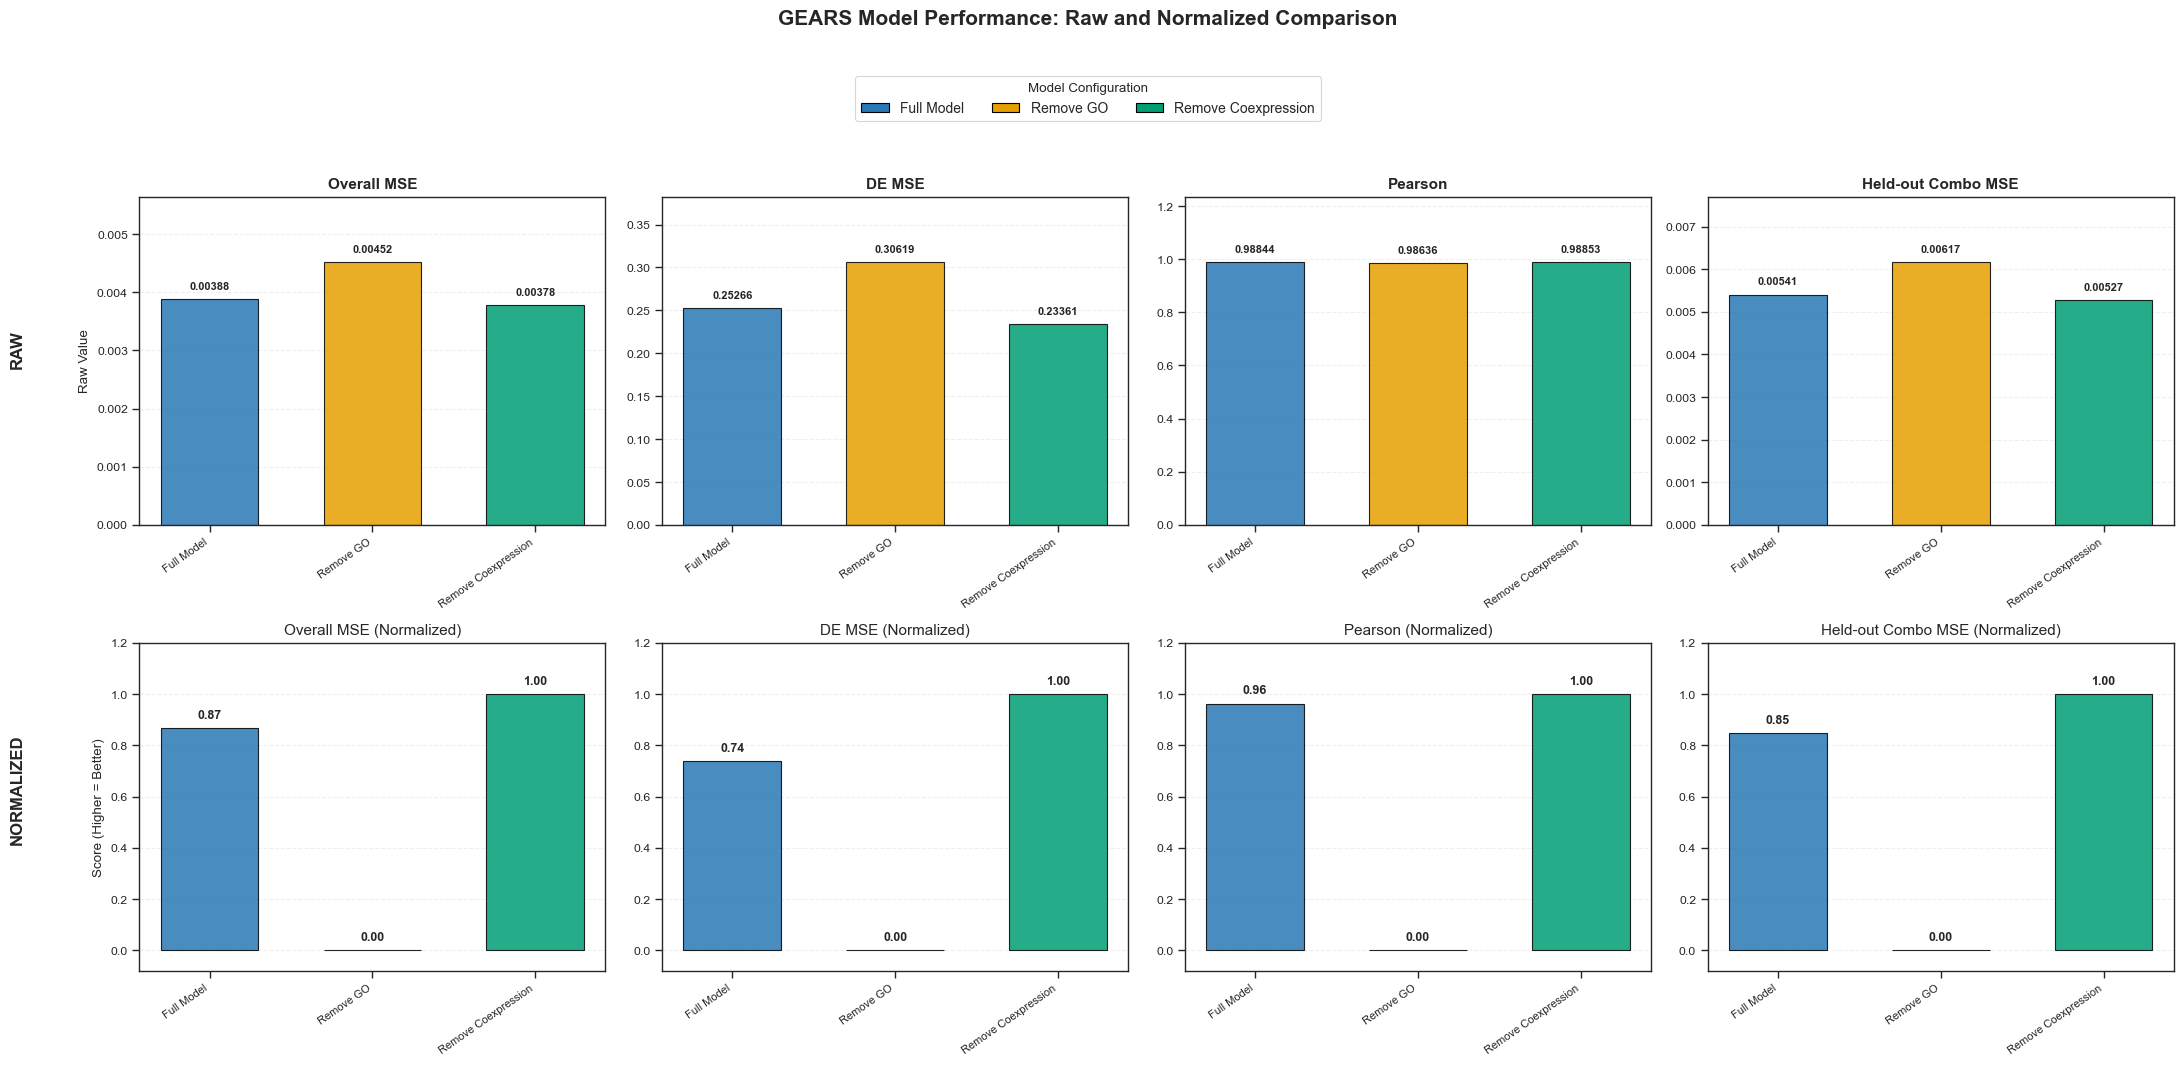

In [61]:
results = [
    model_full_metrix,
    model_remove_go_metrix,
    model_remove_coexpression_metrix
]

df = plot_gears_metrics(results,save_path="comp.png")